In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
data = pd.read_csv("train.csv")
print("Head")
display(data.head())
print("Shape")
display(data.shape)
print("Info")
display(data.info())

Head


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Shape


(1460, 81)

Info
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond   

None

In [3]:
missing = pd.DataFrame({
    "jumlah_missing": data.isnull().sum(),
    "rasio_missing": data.isnull().mean(),
    "tipe_data": data.dtypes
})

missing = missing[missing["jumlah_missing"] > 0]

display(missing)

,jumlah_missing,rasio_missing,tipe_data
LotFrontage,259,0.177397,float64
Alley,1369,0.937671,str
MasVnrType,872,0.597260,str
MasVnrArea,8,0.005479,float64
BsmtQual,37,0.025342,str
BsmtCond,37,0.025342,str
BsmtExposure,38,0.026027,str
BsmtFinType1,37,0.025342,str
BsmtFinType2,38,0.026027,str
Electrical,1,0.000685,str


In [4]:
rasio_missing = data.isnull().mean()
drop_kolom = rasio_missing[rasio_missing > 0.5].index

data = data.drop(columns=drop_kolom)

print("Kolom yang dihapus:", drop_kolom.tolist())
print("Shape setelah penghapusan:", data.shape)

Kolom yang dihapus: ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']
Shape setelah penghapusan: (1460, 76)


In [5]:
ganti_ke_none = [
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'
]
for kolom in ganti_ke_none:
    data[kolom] = data[kolom].fillna('None')

data['Electrical'] = data['Electrical'].fillna(data['Electrical'].mode()[0])
data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
data['GarageYrBlt'] = data['GarageYrBlt'].fillna(0)
data['LotFrontage'] = data.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

data.isnull().sum().sum()

np.int64(0)

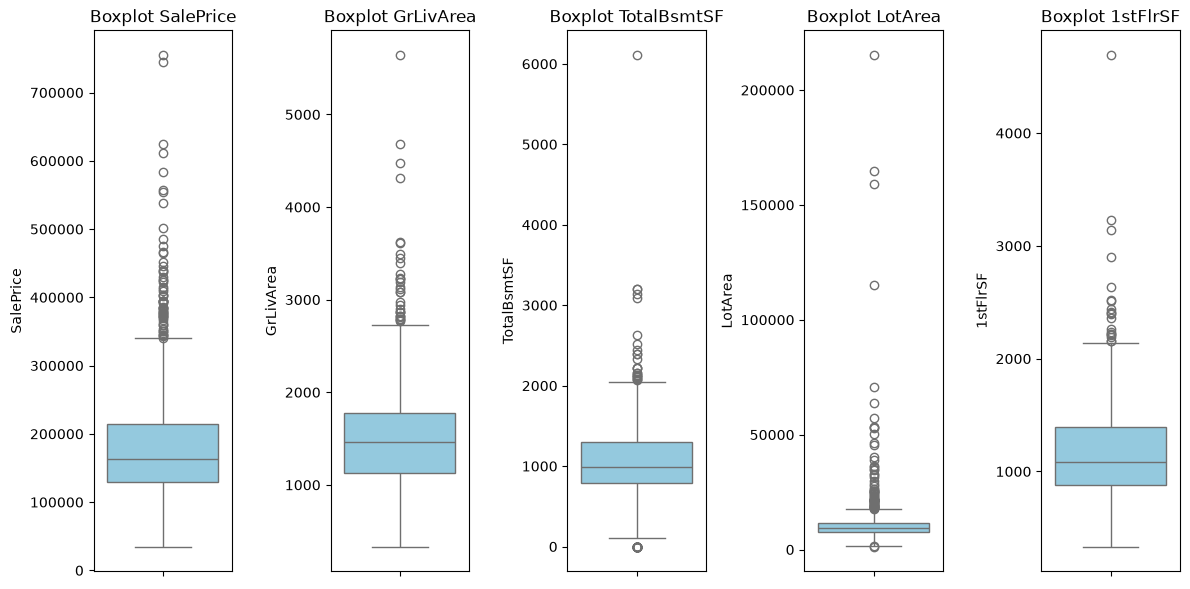

In [6]:
numerik = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'LotArea', '1stFlrSF']

fig, axes = plt.subplots(1, len(numerik), figsize=(12, 6))

for i, kolom in enumerate(numerik):
    sns.boxplot(y=data[kolom], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot {kolom}')

plt.tight_layout()
plt.show()

In [7]:
data = data.drop(data[(data['GrLivArea'] > 4000) & (data['SalePrice'] < 300000)].index)
data['SalePrice'] = np.log1p(data['SalePrice'])

**Alasan penghapusan:** data-data di atas dihapus karena Id 1299: Luas bangunan 5,642 sq ft (terluas di seluruh dataset) dengan skor kualitas 10/10, tetapi harganya hanya $160,000. Id 524: Luas bangunan 4,676 sq ft dengan skor kualitas 10/10, tetapi harganya hanya $184,750.

In [8]:
X = data.drop(columns=['Id', 'SalePrice'])
y = data['SalePrice']

kol_kategorikal = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
kol_numerik = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

X_encoded = pd.get_dummies(X, columns=kol_kategorikal, drop_first=True, dtype=int)

print("Jumlah kolom sebelum encoding:", X.shape[1])
print("Jumlah kolom setelah One-Hot Encoding:", X_encoded.shape[1])

Jumlah kolom sebelum encoding: 74
Jumlah kolom setelah One-Hot Encoding: 242


In [9]:
scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[kol_numerik] = scaler.fit_transform(X_encoded[kol_numerik])

display(X_scaled.head())

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,0.073426,-0.232605,-0.203934,0.658506,-0.517649,1.052959,0.880362,0.523937,0.617283,-0.288867,...,0,0,0,0,1,0,0,0,1,0
1,-0.871868,0.466313,-0.087252,-0.068293,2.177825,0.158428,-0.428115,-0.570739,1.245719,-0.288867,...,0,0,0,0,1,0,0,0,1,0
2,0.073426,-0.092822,0.080162,0.658506,-0.517649,0.986698,0.831900,0.334044,0.108989,-0.288867,...,0,0,0,0,1,0,0,0,1,0
3,0.309749,-0.465578,-0.092325,0.658506,-0.517649,-1.862551,-0.718888,-0.570739,-0.514826,-0.288867,...,0,0,0,0,1,0,0,0,0,0
4,0.073426,0.652691,0.385566,1.385305,-0.517649,0.953567,0.734975,1.384039,0.499451,-0.288867,...,0,0,0,0,1,0,0,0,1,0


In [10]:
corr_matrix = X_scaled.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

threshold = 0.85
to_drop = [column for column in upper.columns if any(upper[column] > threshold)]

print(f"Total fitur yang akan dibuang (korelasi > {threshold}): {len(to_drop)}")
print("\nBeberapa contoh pasangan fitur yang redundant:")
for col in upper.columns:
    high_corr_features = upper.index[upper[col] > threshold].tolist()
    for feat in high_corr_features:
        print(f"  - {feat} <---> {col} (Korelasi: {corr_matrix.loc[feat, col]:.4f})")

X_corr_dropped = X_scaled.drop(columns=to_drop)

print(f"\nShape sebelum eliminasi: {X_scaled.shape}")
print(f"Shape setelah eliminasi: {X_corr_dropped.shape}")

Total fitur yang akan dibuang (korelasi > 0.85): 21

Beberapa contoh pasangan fitur yang redundant:
  - GarageCars <---> GarageArea (Korelasi: 0.8873)
  - MSZoning_FV <---> Neighborhood_Somerst (Korelasi: 0.8628)
  - RoofStyle_Gable <---> RoofStyle_Hip (Korelasi: 0.9331)
  - Exterior1st_CBlock <---> Exterior2nd_CBlock (Korelasi: 1.0000)
  - Exterior1st_CemntBd <---> Exterior2nd_CmentBd (Korelasi: 0.9738)
  - Exterior1st_HdBoard <---> Exterior2nd_HdBoard (Korelasi: 0.8832)
  - Exterior1st_MetalSd <---> Exterior2nd_MetalSd (Korelasi: 0.9731)
  - Exterior1st_VinylSd <---> Exterior2nd_VinylSd (Korelasi: 0.9775)
  - Exterior1st_Wd Sdng <---> Exterior2nd_Wd Sdng (Korelasi: 0.8592)
  - ExterQual_Gd <---> ExterQual_TA (Korelasi: 0.9087)
  - ExterCond_Gd <---> ExterCond_TA (Korelasi: 0.8945)
  - BsmtQual_None <---> BsmtCond_None (Korelasi: 1.0000)
  - BsmtQual_None <---> BsmtExposure_None (Korelasi: 0.9864)
  - BsmtCond_None <---> BsmtExposure_None (Korelasi: 0.9864)
  - BsmtQual_None <---> Bsm

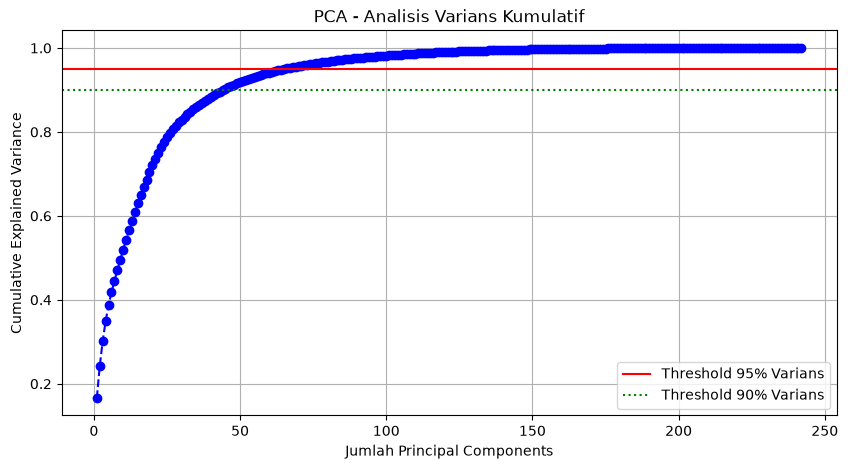

Jumlah komponen yang dipilih untuk mempertahankan 95% varians: 65
Shape matriks X setelah PCA: (1458, 65)


In [11]:
pca_full = PCA().fit(X_scaled)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle='-', label='Threshold 95% Varians')
plt.axhline(y=0.90, color='g', linestyle=':', label='Threshold 90% Varians')
plt.xlabel('Jumlah Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Analisis Varians Kumulatif')
plt.legend(loc='best')
plt.grid(True)
plt.show()

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

n_components = pca.n_components_
print(f"Jumlah komponen yang dipilih untuk mempertahankan 95% varians: {n_components}")
print(f"Shape matriks X setelah PCA: {X_pca.shape}")

In [12]:
nama_kolom_pca = [f'PC_{i+1}' for i in range(X_pca.shape[1])]
df_pca_final = pd.DataFrame(X_pca, columns=nama_kolom_pca)

df_pca_final['SalePrice'] = y.values

df_pca_final.to_csv('5054251038_Jordan Sebastian Simatupang_Tugas_Praproses_Data.csv', index=False)
print("Dataset PCA berhasil disimpan ke '5054251038_Jordan Sebastian Simatupang_Tugas_Praproses_Data.csv'")
print("Shape akhir:", df_pca_final.shape)

Dataset PCA berhasil disimpan ke '5054251038_Jordan Sebastian Simatupang_Tugas_Praproses_Data.csv'
Shape akhir: (1458, 66)
